In [54]:
## Critical Imports
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
import matplotlib.patheffects as PathEffects
import cmasher as cmr

import scipy.constants as const
from scipy.stats import norm
import pandas as pd
from matplotlib.ticker import MultipleLocator, ScalarFormatter
from scipy.signal import find_peaks
from itertools import cycle

# Nested Sampling
import dynesty
import corner
import pickle
import os

#Aesthetics
import matplotlib as mpl
plt.style.use('style.mplstyle')

# My stuff
from TeraToptica import TeraFlashAnalyzer as TFA, TeraFlashConfig as TFC
from TeraToptica import TeraScanAnalyzer as TSA, TeraScanConfig as TSC

window = 'gaussian' # Smoothing window type in frequency domain
window_size  = 15 # Determines how many GHz to smooth the spectrum over (upper bound)

mask_bounds = (
              (0, 150), # mask low frequency HD30_batch2
              (545, 570), (740, 770), (1080, 1245), (1390, 1430), # mask waterlines
              (1585, 1810), (1855, 1950),
            #   (2025, 2075), (2100, 2275), (2325, 2500), (2600, 3000),
              (2000, 10000)
              )

f = np.arange(5, 2000.1, 1)

batches = {}

tf_cfg = TFC(
    window=window,
    window_size=window_size,
    mask_bounds=mask_bounds,
    layout='reference_included'
)

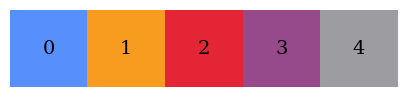

In [55]:
from cmap import Colormap
# cmap = Colormap('colorcet:CET_R1')
# cmap_array = cmap(np.linspace(0, 1, 256))

# entries = 6
# indices = np.linspace(0, len(cmap_array)-1, entries).astype(int)
# colors = cmap_array[indices][::-1]

cmap = Colormap('petroff:petroff6')
colors = cmap(np.linspace(0, 1, 6))

colors = colors[:-1]

# Display for visualization
large_font = 14  # font size for labels
plt.figure(figsize=(5, 1))
plt.imshow([colors], aspect='auto')

for i in range(len(colors)):  # one less because we skipped first color
    plt.annotate(i, (i, 0), color='k', fontsize=large_font, ha='center', va='center')

plt.gca().set_axis_off()

In [56]:
path = './data/20260714'

PP35_batch1_3o2mm = TFA(path, 'PP35_3o2mm_1800-2000ps_1000avgs', config=tf_cfg)

path = './data/20261008'

PP35_3o07mm = TFA(path, 'PP35_3o07mm_1700-1900ps_1000avgs', config=tf_cfg)
PP35_3o12mm = TFA(path, 'PP35_3o12mm_1700-1900ps_1000avgs', config=tf_cfg)
PP35_6o19mm = TFA(path, 'PP35_6o19mm_1700-1900ps_1000avgs', config=tf_cfg)
PP35_6o34mm = TFA(path, 'PP35_6o34mm_1700-1900ps_1000avgs', config=tf_cfg)
PP35_19o32mm = TFA(path, 'PP35_19o32mm_1700-1900ps_1000avgs', config=tf_cfg)

f_3o2mm, t_3o2mm, ut_3o2mm, mask_3o2mm, err_3o2mm, boxnum_3o2mm  = PP35_batch1_3o2mm.get_smoothed_spectra()
f_3o07mm, t_3o07mm, ut_3o07mm, mask_3o07mm, err_3o07mm, boxnum_3o07mm  = PP35_3o07mm.get_smoothed_spectra()
f_3o12mm, t_3o12mm, ut_3o12mm, mask_3o12mm, err_3o12mm, boxnum_3o12mm  = PP35_3o12mm.get_smoothed_spectra()
f_6o19mm, t_6o19mm, ut_6o19mm, mask_6o19mm, err_6o19mm, boxnum_6o19mm  = PP35_6o19mm.get_smoothed_spectra()
f_6o34mm, t_6o34mm, ut_6o34mm, mask_6o34mm, err_6o34mm, boxnum_6o34mm  = PP35_6o34mm.get_smoothed_spectra()
f_19o32mm, t_19o32mm, ut_19o32mm, mask_19o32mm, err_19o32mm, boxnum_19o32mm  = PP35_19o32mm.get_smoothed_spectra()

PP35_batch1 = {}
PP35_batch1['PP35 batch1 0.32 cm'] = {'f': f_3o2mm,  't': t_3o2mm,  'ut': ut_3o2mm,  'mask': mask_3o2mm,  'err': err_3o2mm,  'boxnum': boxnum_3o2mm,  'width': 0.32}

PP35_batch2 = {}
PP35_batch2['PP35 batch2 0.307 cm'] = {'f': f_3o07mm, 't': t_3o07mm, 'ut': ut_3o07mm, 'mask': mask_3o07mm, 'err': err_3o07mm, 'boxnum': boxnum_3o07mm, 'width': 0.307}
PP35_batch2['PP35 batch2 0.312 cm'] = {'f': f_3o12mm, 't': t_3o12mm, 'ut': ut_3o12mm, 'mask': mask_3o12mm, 'err': err_3o12mm, 'boxnum': boxnum_3o12mm, 'width': 0.312}
PP35_batch2['PP35 batch2 0.619 cm'] = {'f': f_6o19mm, 't': t_6o19mm, 'ut': ut_6o19mm, 'mask': mask_6o19mm, 'err': err_6o19mm, 'boxnum': boxnum_6o19mm, 'width': 0.619}
PP35_batch2['PP35 batch2 0.634 cm'] = {'f': f_6o34mm, 't': t_6o34mm, 'ut': ut_6o34mm, 'mask': mask_6o34mm, 'err': err_6o34mm, 'boxnum': boxnum_6o34mm, 'width': 0.634}
PP35_batch2['PP35 batch2 1.932 cm'] = {'f': f_19o32mm, 't': t_19o32mm, 'ut': ut_19o32mm, 'mask': mask_19o32mm, 'err': err_19o32mm, 'boxnum': boxnum_19o32mm, 'width': 1.932}

batches['PP35 batch1'] = PP35_batch1
batches['PP35 batch2'] = PP35_batch2

In [57]:
from matplotlib.colors import to_rgb
import colorsys

def get_cmap_from_color(bname, stop_color, start_v=1, stop_v=0.5):       
    sample_dict = batches[bname]
    keys = list(sample_dict.keys())
    N    = len(keys)

    r, g, b = to_rgb(stop_color)
    h, s, _ = colorsys.rgb_to_hsv(r, g, b)

    v_values = np.linspace(start_v, stop_v, N)

    for sname, v in zip(keys, v_values):
        sample_dict[sname]["color"] = colorsys.hsv_to_rgb(h, s, v)

for bname, b in batches.items():
    for sample in b:
        b[sample]['t'] = np.where((b[sample]['t'] < 0), np.nan, b[sample]['t'])  # Set negative transmission values to zero
        b[sample]['ut'] = np.where((b[sample]['ut'] < 0), np.nan, b[sample]['ut'])  # Set negative transmission values to zero

        b[sample]['alpha'] = -np.log(b[sample]['t'])/b[sample]['width']                  # Calculate attenuation
        b[sample]['alpha_unsmoothed'] = -np.log(b[sample]['ut'])/(1/b[sample]['width'])  # Calculate attenuation without smoothing

        b[sample]['f_binned']  = b[sample]['f'][~b[sample]['mask']][::b[sample]['boxnum']]
        b[sample]['t_binned']  = b[sample]['t'][~b[sample]['mask']][::b[sample]['boxnum']]
        b[sample]['alpha_binned'] = b[sample]['alpha'][~b[sample]['mask']][::b[sample]['boxnum']]

    if bname == 'PP35 batch1':
        stop_color = colors[0]
    elif bname == 'PP35 batch2':
        stop_color = colors[2]
    else:
        stopcolor ='k' #Shouldn't occur

    get_cmap_from_color(bname, stop_color)

In [58]:
## Saved R+M+a_RM fits from main.ipynb (gated, GATE_END_PS = 120). Bands use 4000 random posterior draws
from fitting_funcs import alpha_batch_params, components_batch_params

w = 5 # 5 cm assembly example
rng = np.random.default_rng(0)

models = {}
for bname in batches:
    with open(f"pkls/{bname.replace(' ', '_')}_model_fp_g120.pkl", 'rb') as file:
        fit = pickle.load(file)

    results = fit['results']
    samples = dynesty.utils.resample_equal(results.samples, np.exp(results['logwt'] - results['logz'][-1]))
    draws   = samples[rng.choice(len(samples), size=4000, replace=False)]
    n_eff   = fit['meta']['n_eff']

    m = {}
    m['alpha_lower'], m['alpha'], m['alpha_upper'] = np.percentile(alpha_batch_params(f, draws, n_eff), [16, 50, 84], axis=0)

    # Loss through 5 cm; absorption uses the fitted tan_delta
    Abs_s, Ray_s, Mie_s, res_s = components_batch_params(f, draws, w, n_eff)
    for name, arr in zip(['Abs', 'Ray', 'Mie'], [Abs_s, Ray_s, Mie_s]):
        m[f'{name}_lower'], m[name], m[f'{name}_upper'] = np.percentile(arr, [16, 50, 84], axis=0)

    models[bname] = m

PP35 batch1
PP35 batch2


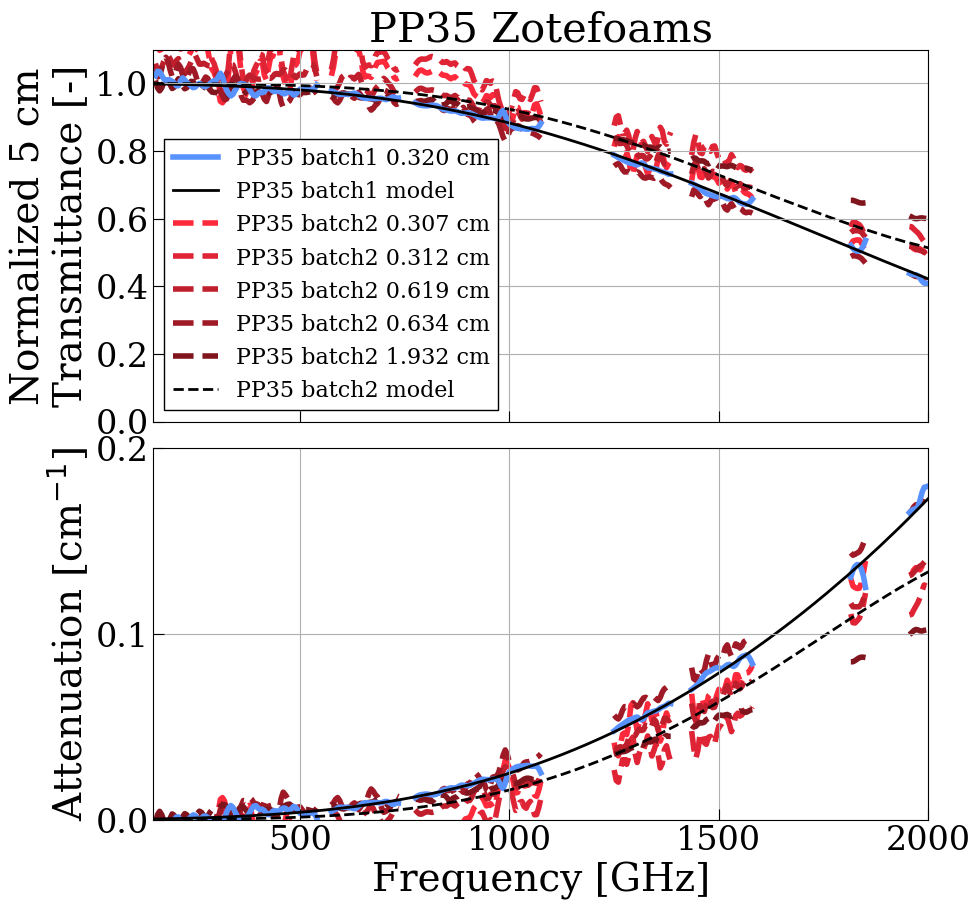

In [65]:
fig, axes = plt.subplots(2, 1, figsize=(10, 10), sharex=True, sharey='row')
ax0, ax1 = axes

lw = 4
plt.xlim(150, 2000)
ax0.set_ylim(0, 1.1)
ax1.set_ylim(0, 0.2)
ax0.set_ylabel('Normalized 5 cm\nTransmittance [-]', fontsize=28)
ax1.set_ylabel(r'Attenuation [cm$^{-1}$]', fontsize=28)
ax1.set_xlabel('Frequency [GHz]', fontsize=28)

for bname, b in batches.items():
    print(bname)

    for j, sample in enumerate(b):

        f_    = b[sample]['f']
        t     = b[sample]['t']
        alpha = b[sample]['alpha']
        err   = b[sample]['err']
        mask  = b[sample]['mask']

        width = b[sample]['width']

        t_5cm_masked = np.where(mask, np.nan, t**(5/width))
        alpha_masked = np.where(mask, np.nan, alpha)

        color = b[sample]['color']

        zorder=-9 if bname == 'PP35 batch1' else -10
        ls = '--' if bname == 'PP35 batch2' else '-'

        ax0.plot(f_, t_5cm_masked, color=color, ls=ls, lw=lw, zorder=zorder, label=f'{bname} {width:.3f} cm')
        ax1.plot(f_, alpha_masked, color=color, ls=ls, lw=lw, zorder=zorder) #, label=f'{bname} {width:.3f} cm')

        i += 1

    ## R+M+a_RM fit: posterior median (black) and 16-84 % band
    m = models[bname]
    color = colors[0] if bname == 'PP35 batch1' else colors[2]
    # ax0.fill_between(f, np.exp(-5*m['alpha_upper']), np.exp(-5*m['alpha_lower']), color=color, alpha=0.5, lw=0, zorder=-11)
    ax0.plot(f, np.exp(-5*m['alpha']), color='k', ls=ls, lw=2, zorder=-8, label=f'{bname} model')
    # ax1.fill_between(f, m['alpha_lower'], m['alpha_upper'], color=color, alpha=0.5, lw=0, zorder=-11)
    ax1.plot(f, m['alpha'], color='k', ls=ls, lw=2, zorder=-8)

for ax in axes.flatten():
    ax.grid(True)

ax0.legend(loc='lower left', fontsize=16, framealpha=1, edgecolor='black', facecolor='white', fancybox=False)

ax0.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax1.set_yticks([0, 0.1, 0.2])
ax0.set_title('PP35 Zotefoams', fontsize=30)

plt.gcf().set_facecolor('white')
plt.subplots_adjust(wspace=0.07, hspace=0.07)
plt.show()

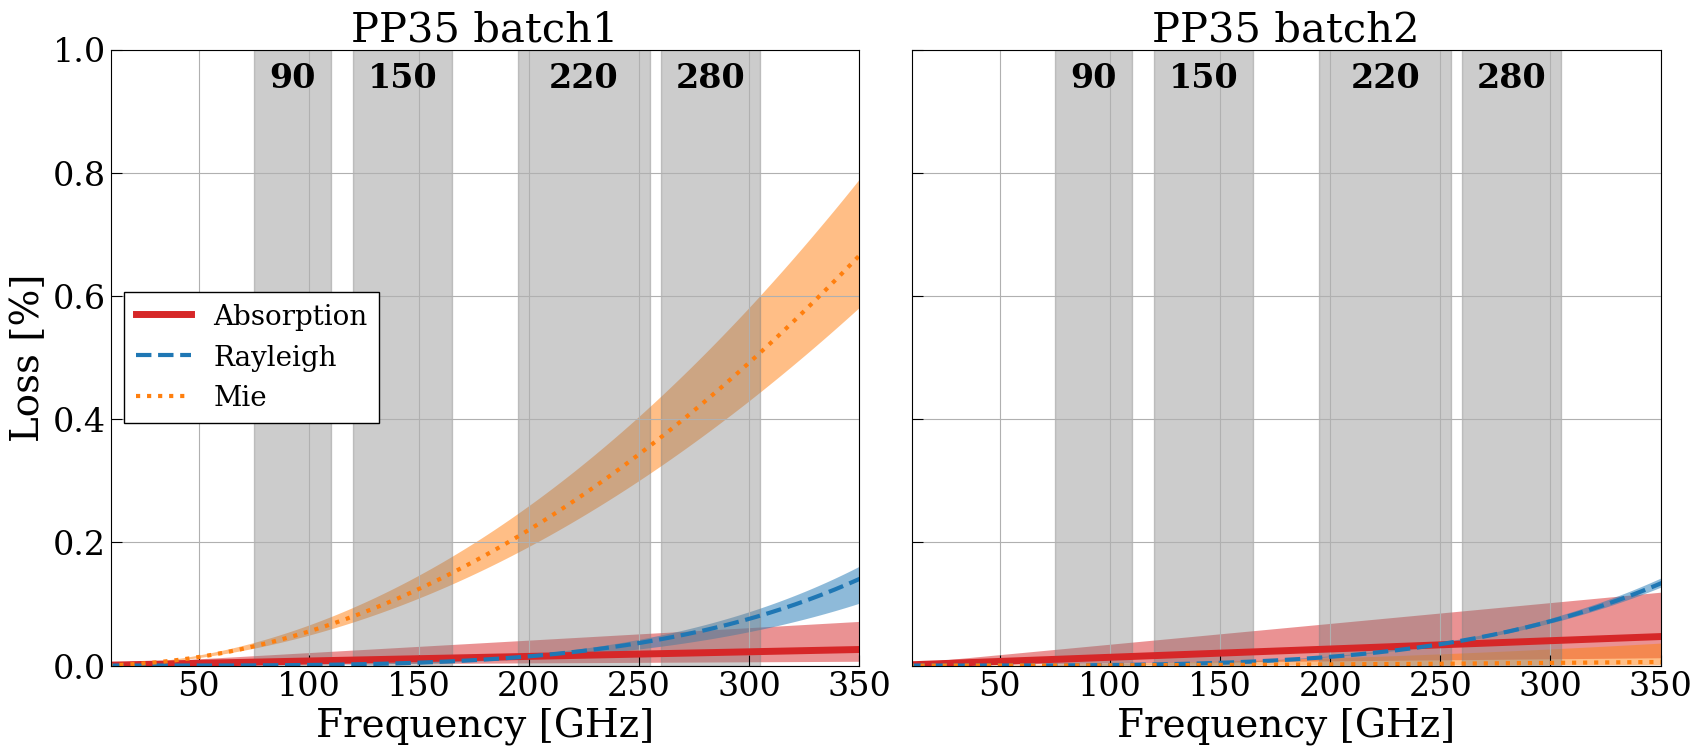

In [60]:
## R+M+a_RM loss components through 5 cm: PP35 batch 1 (left) and batch 2 (right)
fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharex=True, sharey=True)

for ax, (bname, m) in zip(axes, models.items()):
    for name, label, color, ls, lw_ in [('Abs', 'Absorption', 'tab:red', '-', 5), ('Ray', 'Rayleigh', 'tab:blue', '--', 3), ('Mie', 'Mie', 'tab:orange', ':', 3)]:
        ax.plot(f, m[name], color=color, ls=ls, lw=lw_, zorder=2, label=label)
        ax.fill_between(f, m[f'{name}_lower'], m[f'{name}_upper'], color=color, edgecolor='none', alpha=0.5, zorder=0)

    for band, (lbound, ubound) in {'90': (75, 110), '150': (120, 165), '220': (195, 255), '280': (260, 305)}.items():
        ax.axvspan(lbound, ubound, alpha=0.4, color='gray', zorder=0)
        ax.text((lbound + ubound)/2, 0.98, band, transform=ax.get_xaxis_transform(), color='k', ha='center', va='top', fontsize=24, fontweight='bold')

    ax.set_title(bname, fontsize=30)
    ax.set_xlabel('Frequency [GHz]', fontsize=28)
    ax.grid(True)

axes[0].set_xlim(10, 350)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel('Loss [%]', fontsize=28)
axes[0].legend(loc='center left', fontsize=20, framealpha=1, edgecolor='black', facecolor='white', fancybox=False)

plt.gcf().set_facecolor('white')
plt.subplots_adjust(wspace=0.07)
plt.savefig('components-pp35.pdf')
plt.show()